In [1]:
import pandas as pd
from rdkit import Chem
from rdkit.Chem import PandasTools
from rdkit.Chem import rdMolDescriptors
import numpy as np
import datamol as dm

In [2]:
from tqdm.auto import tqdm

tqdm.pandas()

In [3]:
bd_df = pd.read_csv("D2.csv")

/tmp/ipykernel_615945/3285881992.py:1: DtypeWarning: Columns (45,46) have mixed types. Specify dtype option on import or set low_memory=False.
  bd_df = pd.read_csv("D2.csv")


In [4]:
bd_df.shape

(24742, 50)

In [5]:
bd_df.columns

Index(['BindingDB Reactant_set_id', 'Ligand SMILES', 'Ligand InChI',
       'Ligand InChI Key', 'BindingDB MonomerID', 'BindingDB Ligand Name',
       'Target Name',
       'Target Source Organism According to Curator or DataSource', 'Ki (nM)',
       'IC50 (nM)', 'Kd (nM)', 'EC50 (nM)', 'kon (M-1-s-1)', 'koff (s-1)',
       'pH', 'Temp (C)', 'Curation/DataSource', 'Article DOI',
       'BindingDB Entry DOI', 'PMID', 'PubChem AID', 'Patent Number',
       'Authors', 'Institution', 'Link to Ligand in BindingDB',
       'Link to Target in BindingDB',
       'Link to Ligand-Target Pair in BindingDB', 'Ligand HET ID in PDB',
       'PDB ID(s) for Ligand-Target Complex', 'PubChem CID', 'PubChem SID',
       'ChEBI ID of Ligand', 'ChEMBL ID of Ligand', 'DrugBank ID of Ligand',
       'IUPHAR_GRAC ID of Ligand', 'KEGG ID of Ligand', 'ZINC ID of Ligand',
       'Number of Protein Chains in Target (>1 implies a multichain complex)',
       'BindingDB Target Chain Sequence', 'PDB ID(s) of Target

In [6]:
bd_df['Target Name'].unique()

array(['D(2) dopamine receptor'], dtype=object)

<Axes: >

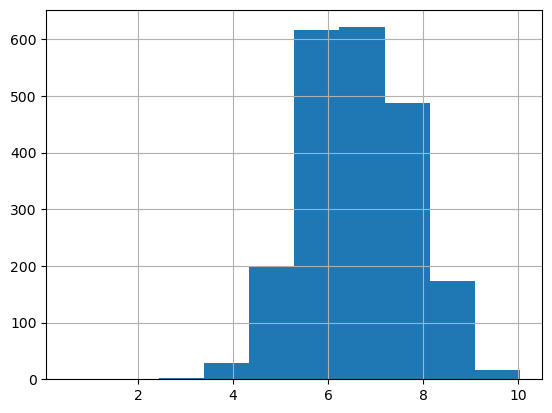

In [17]:
(bd_df
 .query("`IC50 (nM)` != ''")
 #.query("`Target Name` == 'Tyrosine-protein kinase SYK'")
 [['Ligand SMILES', 'IC50 (nM)', 'BindingDB Ligand Name']]
 .rename(columns={'Ligand SMILES': 'SMILES'})
 .astype({'SMILES': str, 'IC50 (nM)':str, 'BindingDB Ligand Name':str})
 .drop_duplicates('SMILES')
 .query("~`IC50 (nM)`.str.contains('<|>')")
 .query("~SMILES.str.contains('.', regex=False)")
 .astype({'IC50 (nM)':float, 'SMILES': str})
 .assign(IC50= lambda adf: adf['IC50 (nM)'].apply(lambda x: x if x>0 else None))
 .assign(pIC50= lambda adf: adf.IC50.pipe(dm.molar.molar_to_log, 'nM'))
 ['pIC50']
 .hist()
)

In [26]:
(bd_df
 .query("`IC50 (nM)` != ''")
 [['Ligand SMILES', 'IC50 (nM)', 'BindingDB Ligand Name']]
 .rename(columns={'Ligand SMILES': 'SMILES'})
 .astype({'SMILES': str, 'IC50 (nM)':str, 'BindingDB Ligand Name':str})
 .drop_duplicates('SMILES')
 .query("~`IC50 (nM)`.str.contains('<|>')")
 .query("~SMILES.str.contains('.', regex=False)")
 .astype({'IC50 (nM)':float, 'SMILES': str})
 .assign(IC50= lambda adf: adf['IC50 (nM)'].apply(lambda x: x if x>0 else None))
 .assign(pIC50= lambda adf: adf.IC50.pipe(dm.molar.molar_to_log, 'nM'))
 .query('~IC50.isna()')
 [["SMILES", "pIC50"]]
 .assign(name= lambda adf: [f"dop_{x}" for x in range(len(adf))])
 .reset_index(drop=True)
).to_csv('dop_train.csv', index=False)

## ML workflow
- Feature generation from SMILES
- Data preprocessing
- ML pipeline setup with cross-validation and grid search
- Model training and evaluation
- Model comparison

In [53]:
df = pd.read_csv('dop_train.csv')

In [8]:
df.head()

,SMILES,pIC50,name
0,CC(C)(C)c1nc(cc(n1)C(F)(F)F)N1CCN(CCCCNC(=O)c2...,5.638272,dop_0
1,COc1ccc(nc1)C1CCN(CCCc2nc3ccccc3s2)CC1,5.630784,dop_1
2,C(Oc1ccc2[nH]ccc2c1)C1CCN(CC2CC2)CC1,5.629117,dop_2
3,CN(CCCN1CCC(CC1)C(=O)c1ccc(F)cc1)C(=O)c1noc2cc...,5.623806,dop_3
4,COc1c(Cl)cc(Cl)c(OC)c1C(=O)NC[C@H]1CCCN1Cc1ccc...,5.623423,dop_4


In [54]:
df.shape

(2145, 3)

In [8]:
df.query("index == 420")

,SMILES,pIC50,ID
420,Cn1cnc2cc(-c3ccc(N4CCOCC4)cc3)nc(N3CC(CO)C3)c2...,6.590067,db_420


In [9]:
df.dtypes

SMILES     object
pIC50     float64
ID         object
dtype: object

**I will use the above descriptors to create models**

In [13]:
dm.list_supported_fingerprints()

{'maccs': <function rdkit.Chem.rdMolDescriptors.GetMACCSKeysFingerprint>,
 'pattern': <function rdkit.Chem.rdmolops.PatternFingerprint>,
 'layered': <function rdkit.Chem.rdmolops.LayeredFingerprint>,
 'erg': <function rdkit.Chem.rdReducedGraphs.GetErGFingerprint>,
 'estate': <function datamol.fp.<lambda>(x, **args)>,
 'avalon-count': <function rdkit.Avalon.pyAvalonTools.GetAvalonCountFP>,
 'ecfp': <function rdkit.Chem.rdFingerprintGenerator.GetMorganGenerator>,
 'fcfp': <function rdkit.Chem.rdFingerprintGenerator.GetMorganGenerator>,
 'topological': <function rdkit.Chem.rdFingerprintGenerator.GetTopologicalTorsionGenerator>,
 'atompair': <function rdkit.Chem.rdFingerprintGenerator.GetAtomPairGenerator>,
 'rdkit': <function rdkit.Chem.rdFingerprintGenerator.GetRDKitFPGenerator>,
 'ecfp-count': <function rdkit.Chem.rdFingerprintGenerator.GetMorganGenerator>,
 'fcfp-count': <function rdkit.Chem.rdFingerprintGenerator.GetMorganGenerator>,
 'topological-count': <function rdkit.Chem.rdFinger

**I will use the above Fingerprints to create models**

In [25]:
property_names = list(rdMolDescriptors.Properties.GetAvailableProperties())
property_getter = rdMolDescriptors.Properties(property_names)

In [26]:
len(property_names)

43

In [27]:
def smi2props(smi):
    mol = Chem.MolFromSmiles(smi)
    props = None
    if mol:
        Chem.DeleteSubstructs(mol, Chem.MolFromSmarts("[#1X0]"))
        props = np.array(property_getter.ComputeProperties(mol))
    return props

In [55]:
df['props'] = df.SMILES.progress_apply(safe_smi2props)

  0%|          | 0/2145 [00:00<?, ?it/s]

[16:41:50] Explicit valence for atom # 1 N, 4, is greater than permitted


In [56]:
df = df.query("~props.isna()")

In [57]:
df[property_names] = df['props'].to_list()

In [58]:
# The second time
df = df.drop(columns='props')

In [44]:
df.head()

,SMILES,pIC50,name,exactmw,amw,lipinskiHBA,lipinskiHBD,NumRotatableBonds,NumHBD,NumHBA,...,chi0n,chi1n,chi2n,chi3n,chi4n,hallKierAlpha,kappa1,kappa2,kappa3,Phi
0,CC(C)(C)c1nc(cc(n1)C(F)(F)F)N1CCN(CCCCNC(=O)c2...,5.638272,dop_0,503.262043,503.573,8.0,1.0,7.0,1.0,7.0,...,20.846379,12.165716,6.153468,6.153468,4.074584,-3.21,25.870158,10.416140,6.312929,7.485200
1,COc1ccc(nc1)C1CCN(CCCc2nc3ccccc3s2)CC1,5.630784,dop_1,367.171833,367.518,4.0,0.0,6.0,0.0,5.0,...,15.226687,9.383757,5.203940,5.203940,3.687061,-1.98,17.434639,8.144550,4.048891,5.461434
2,C(Oc1ccc2[nH]ccc2c1)C1CCN(CC2CC2)CC1,5.629117,dop_2,284.188863,284.403,3.0,1.0,5.0,1.0,2.0,...,12.553768,8.289690,4.930933,4.930933,3.336488,-1.48,13.201552,5.721854,3.236139,3.597017
3,CN(CCCN1CCC(CC1)C(=O)c1ccc(F)cc1)C(=O)c1noc2cc...,5.623806,dop_3,423.195820,423.488,6.0,0.0,7.0,0.0,5.0,...,17.590250,10.647156,5.981708,5.981708,4.122556,-3.06,21.182683,9.388959,4.823588,6.415591
4,COc1c(Cl)cc(Cl)c(OC)c1C(=O)NC[C@H]1CCCN1Cc1ccc...,5.623423,dop_4,440.106976,441.330,5.0,1.0,7.0,1.0,4.0,...,16.305487,9.308791,5.072951,5.072951,3.647343,-2.02,21.683205,9.653396,4.942288,7.217812


In [79]:
df.shape

(2144, 47)

In [90]:
df.isna().sum()

SMILES                             0
pIC50                              0
name                               0
exactmw                            0
amw                                0
lipinskiHBA                        0
lipinskiHBD                        0
NumRotatableBonds                  0
NumHBD                             0
NumHBA                             0
NumHeavyAtoms                      0
NumAtoms                           0
NumHeteroatoms                     0
NumAmideBonds                      0
FractionCSP3                       0
NumRings                           0
NumAromaticRings                   0
NumAliphaticRings                  0
NumSaturatedRings                  0
NumHeterocycles                    0
NumAromaticHeterocycles            0
NumSaturatedHeterocycles           0
NumAliphaticHeterocycles           0
NumSpiroAtoms                      0
NumBridgeheadAtoms                 0
NumAtomStereoCenters               0
NumUnspecifiedAtomStereoCenters    0
l

## First Impressions

In [37]:
from lightgbm import LGBMRegressor, plot_importance #LightGBM models
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.metrics import r2_score, mean_squared_error #ML stats
import seaborn as sns #Plotting
from yellowbrick.regressor import prediction_error, ResidualsPlot

In [59]:
train, test = train_test_split(df, test_size=0.2)

In [60]:
train_x = train[property_names]
train_y = train.pIC50.astype(float)
test_x = test[property_names]
test_y = test.pIC50.astype(float)

In [61]:
lgbm = LGBMRegressor()

In [62]:
lgbm.fit(train_x, train_y)

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001355 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 5683
[LightGBM] [Info] Number of data points in the train set: 1715, number of used features: 43
[LightGBM] [Info] Start training from score 6.608532


LGBMRegressor()

In [63]:
pred = lgbm.predict(test_x)

In [64]:
r2_score(test_y, pred)

0.4455930046606851

In [65]:
mean_squared_error(test_y,pred,squared=False)

0.7892439352302232

[Text(0, 0.5, 'Predicted pic50')]

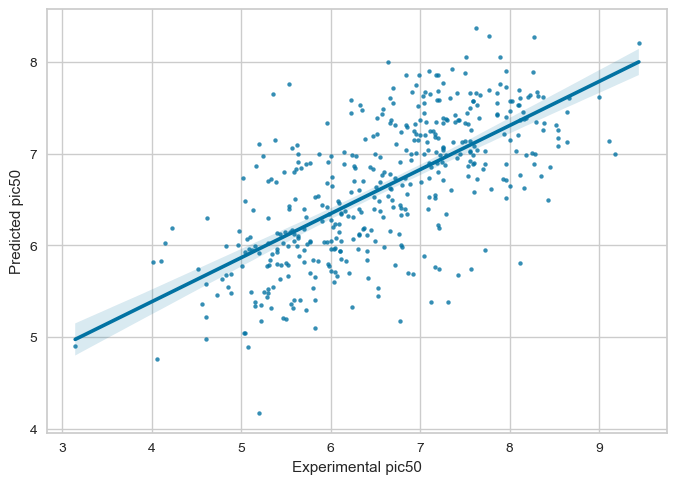

In [66]:
ax = sns.regplot(x=test_y,y=pred,scatter_kws={'s':10})
ax.set(xlabel="Experimental pic50")
ax.set(ylabel="Predicted pic50")

<Axes: title={'center': 'Feature importance'}, xlabel='Feature importance', ylabel='Features'>

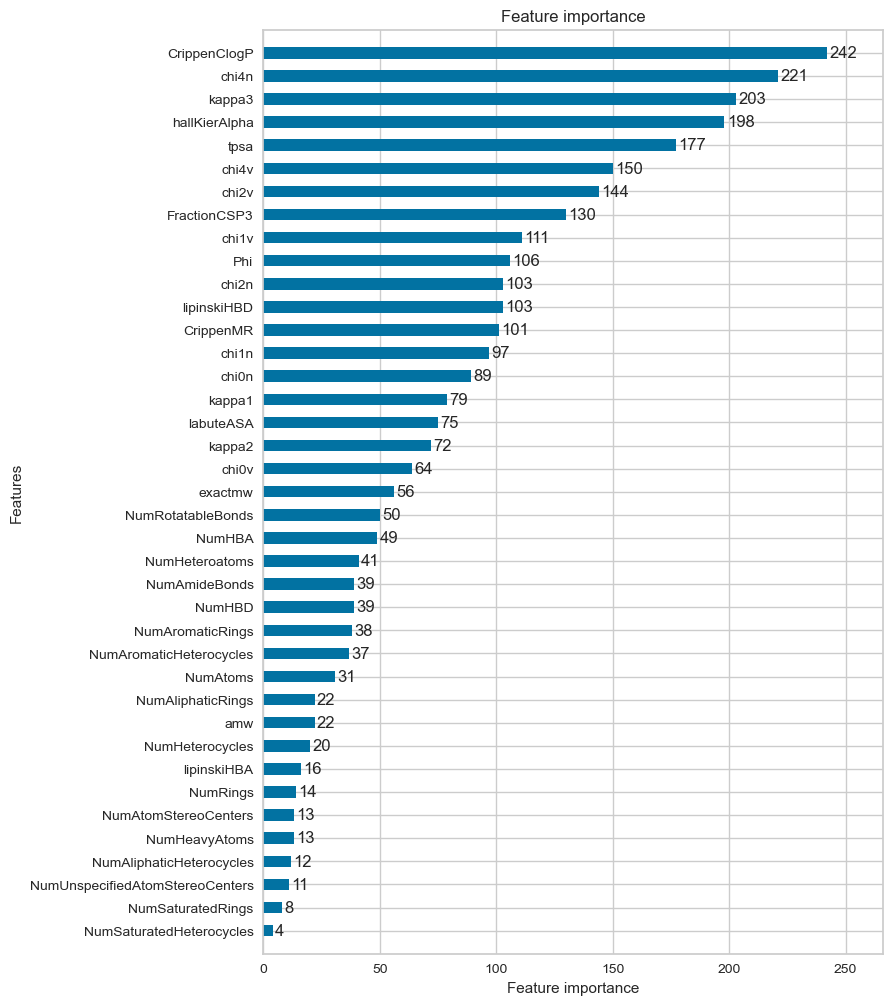

In [26]:
plot_importance(lgbm, figsize=(8,12),height=0.5)

In [27]:
imp_fs = {k: v for k, v in sorted((dict(zip(lgbm.feature_name_, lgbm.feature_importances_))).items(), key=lambda item: item[1], reverse=True)}

In [47]:
fingerprints = ['maccs', 'pattern', 'layered', 'erg','estate', 'ecfp', 'fcfp', 'topological', 'atompair', 'rdkit', 'ecfp-count', 'fcfp-count','topological-count', 'atompair-count', 'rdkit-count', 'avalon-count']

In [28]:
", ".join(fingerprints)

'maccs, pattern, layered, erg, estate, ecfp, fcfp, topological, atompair, rdkit, ecfp-count, fcfp-count, topological-count, atompair-count, rdkit-count, avalon-count'

In [48]:
def test_fp(df):
    df['mol'] = df.SMILES.apply(Chem.MolFromSmiles)
    r2s = []
    mses = []
    for fp in fingerprints:
        curr_df = df.copy()
        curr_df['mol'] = df.SMILES.apply(Chem.MolFromSmiles)
        curr_df['fp'] = df.mol.apply(dm.to_fp, fp_type=fp)
        print("the fp in use: ", fp)
        print("Train test split process ")
        train, test = train_test_split(curr_df, test_size=0.2, random_state=99)
        train_x = train['fp'].to_list()
        train_y = train.pIC50
        test_x = test['fp'].to_list()
        test_y = test.pIC50
        print("train size, ", len(train_x), "test size, ", len(test_x))
        lgbm = LGBMRegressor()
        lgbm.fit(train_x, train_y)
        pred = lgbm.predict(test_x)
        curr_r2 = r2_score(test_y, pred)
        curr_mse = mean_squared_error(test_y,pred,squared=False)
        print(curr_r2)
        print(curr_mse)
        r2s.append(curr_r2)
        mses.append(curr_mse)
    return r2s, mses

In [67]:
r2s, mses = test_fp(df)

the fp in use:  maccs
Train test split process 
train size,  1715 test size,  429
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001782 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 244
[LightGBM] [Info] Number of data points in the train set: 1715, number of used features: 122
[LightGBM] [Info] Start training from score 6.623318
0.5396349567204877
0.7472402321165663
the fp in use:  pattern
Train test split process 
train size,  1715 test size,  429
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.089203 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2512
[LightGBM] [Info] Number of data points in the train set: 1715, number of used features: 1256
[LightGBM] [Info] Start training from

In [68]:
import matplotlib.pyplot as plt

In [52]:
import collections

In [56]:
dict(zip(fingerprints, r2s))

{'maccs': 0.5105923891130195,
 'pattern': 0.6422691781708526,
 'layered': 0.6781962242041473,
 'erg': 0.657918523414083,
 'estate': 0.5300825301522065,
 'ecfp': 0.6869354603276621,
 'fcfp': 0.6715305436497221,
 'topological': 0.6752867991897893,
 'atompair': 0.6718822816462459,
 'rdkit': 0.6956852874412938,
 'ecfp-count': 0.6953946354522187,
 'fcfp-count': 0.674647366334684,
 'topological-count': 0.6734763699524082,
 'atompair-count': 0.6986883299195314,
 'rdkit-count': 0.6959107217326337,
 'avalon-count': 0.6797382804793992}

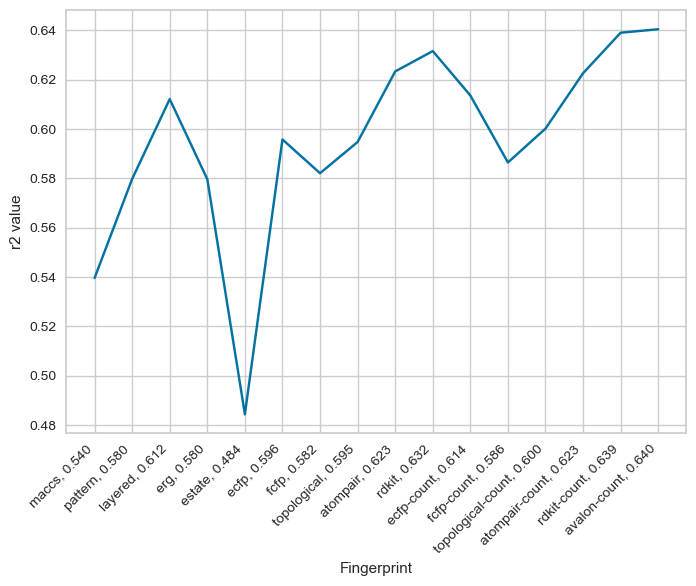

In [70]:
ax = sns.lineplot(x=[f"{x}, {y:.3f}" for x,y in zip(fingerprints, r2s)], y=r2s)
#ax.lineplot(
ax.set(xlabel='Fingerprint')
ax.set(ylabel='r2 value')
plt.xticks(rotation=45, ha='right')
plt.show()


In [71]:
selected_fps = ['pattern', 'ecfp', 'fcfp', 'topological', 'rdkit', 'ecfp-count', 'fcfp-count','topological-count', 'atompair-count', 'rdkit-count', 'avalon-count']

In [72]:
from sklearn.metrics import mean_absolute_error
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
import xgboost as xgb

Comparing different regressors

In [1]:
def test_naive_(df, model, selected_fps, selected_desc):
    df['mol'] = df.SMILES.apply(Chem.MolFromSmiles)
    r2s = []
    mses = []
    for sfp in selected_fps:
        curr_df = df.copy()
        curr_df['mol'] = df.SMILES.apply(Chem.MolFromSmiles)
        curr_df['fp'] = df.mol.apply(dm.to_fp, fp_type=sfp)
        curr_fp_df = pd.DataFrame(curr_df['fp'].to_list(), columns=[f'fp{x}' for x in range(len(curr_df['fp'].values[0]))])
        curr_df = pd.concat([curr_df[[*selected_desc, 'SMILES', 'pIC50']], curr_fp_df], axis=1)
        del curr_fp_df
        print("the fp in use: ", sfp)
        print("Train test split process ")
        train, test = train_test_split(curr_df, test_size=0.2, random_state=99)
        train_x = train.drop(columns=['SMILES', 'pIC50'])
        train_y = train.pIC50
        test_x = test.drop(columns=['SMILES', 'pIC50'])
        test_y = test.pIC50
        print("train size, ", len(train_x), "test size, ", len(test_x))
        model.fit(train_x, train_y)
        pred = model.predict(test_x)
        curr_r2 = r2_score(test_y, pred)
        curr_mse = mean_squared_error(test_y,pred,squared=False)
        print(curr_r2)
        print(curr_mse)
        r2s.append(curr_r2)
        mses.append(curr_mse)

Each time the first number is r2 and the second number is mse

In [91]:
lgbm_new = LGBMRegressor()

In [92]:
test_naive_(df, lgbm_new, selected_fps, property_names)

the fp in use:  pattern
Train test split process 
train size,  1716 test size,  429
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.045744 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 8208
[LightGBM] [Info] Number of data points in the train set: 1716, number of used features: 1292
[LightGBM] [Info] Start training from score 6.616147
0.6655884324644349
0.6538902941731699
the fp in use:  ecfp
Train test split process 
train size,  1716 test size,  429
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.080124 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 8116
[LightGBM] [Info] Number of data points in the train set: 1716, number of used features: 1246
[LightGBM] [Info] Start training fro

In [82]:
rfreg = RandomForestRegressor(n_estimators=200)

In [83]:
test_naive_(df, rfreg, fingerprints, property_names)

the fp in use:  maccs
Train test split process 
train size,  1716 test size,  429


ValueError: Input X contains NaN.
RandomForestRegressor does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values

In [85]:
xgb_reg = xgb.XGBRegressor(n_estimators=200)

In [86]:
test_naive_(df, xgb_reg, selected_fps, property_names)

the fp in use:  pattern
Train test split process 
train size,  1716 test size,  429


XGBoostError: [16:57:30] /home/conda/feedstock_root/build_artifacts/xgboost-split_1748292990656/work/src/data/data.cc:550: Check failed: valid: Label contains NaN, infinity or a value too large.
Stack trace:
  [bt] (0) /home/ramin/miniconda3/envs/cheminfoenv/lib/libxgboost.so(dmlc::LogMessageFatal::~LogMessageFatal()+0x6e) [0x7f04c481eb4e]
  [bt] (1) /home/ramin/miniconda3/envs/cheminfoenv/lib/libxgboost.so(xgboost::MetaInfo::SetInfoFromHost(xgboost::Context const*, xgboost::StringView, xgboost::Json)+0xba9) [0x7f04c4ae99f9]
  [bt] (2) /home/ramin/miniconda3/envs/cheminfoenv/lib/libxgboost.so(xgboost::MetaInfo::SetInfo(xgboost::Context const&, xgboost::StringView, xgboost::StringView)+0x375) [0x7f04c4aeb725]
  [bt] (3) /home/ramin/miniconda3/envs/cheminfoenv/lib/libxgboost.so(XGDMatrixSetInfoFromInterface+0x9d) [0x7f04c476c15d]
  [bt] (4) /home/ramin/miniconda3/envs/cheminfoenv/lib/python3.12/lib-dynload/../../libffi.so.8(+0x6a4a) [0x7f05d17bea4a]
  [bt] (5) /home/ramin/miniconda3/envs

In [212]:
svrreg = SVR()

In [213]:
test_naive_(fp_desc_df, svrreg, selected_fps, selected_desc)

/tmp/ipykernel_3043603/1137254797.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['mol'] = df.SMILES.apply(Chem.MolFromSmiles)


the fp in use:  avalon-count
Train test split process 
train size,  1368 test size,  342
0.7388005121456817
0.6912285068070443
the fp in use:  ecfp-count
Train test split process 
train size,  1368 test size,  342
0.4871155229488341
0.968601767955163
the fp in use:  ecfp
Train test split process 
train size,  1368 test size,  342
0.43506816456824826
1.0165611413007654


In [214]:
elasticreg = ElasticNet()

In [215]:
test_naive_(fp_desc_df, elasticreg, selected_fps, selected_desc)

/tmp/ipykernel_3043603/1137254797.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['mol'] = df.SMILES.apply(Chem.MolFromSmiles)


the fp in use:  avalon-count
Train test split process 
train size,  1368 test size,  342
0.6214055551200198
0.8321902027207663
the fp in use:  ecfp-count
Train test split process 
train size,  1368 test size,  342
0.3009169393421949
1.1308366345364664
the fp in use:  ecfp
Train test split process 
train size,  1368 test size,  342
0.21556522261445543
1.1978816158190821


In [120]:
lassoreg = Lasso()

In [121]:
test_naive_(df, lassoreg, selected_fps, selected_desc)

the fp in use:  ecfp-count
Train test split process 
train size,  1368 test size,  342
0.21668006729624179
1.1970300939249663
the fp in use:  ecfp
Train test split process 
train size,  1368 test size,  342
0.21668006729624179
1.1970300939249663


In [216]:
ridgereg = Ridge()

In [219]:
test_naive_(fp_desc_df, ridgereg, selected_fps, selected_desc)

/tmp/ipykernel_3043603/1137254797.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['mol'] = df.SMILES.apply(Chem.MolFromSmiles)


the fp in use:  avalon-count
Train test split process 
train size,  1368 test size,  342
0.5847110694779197
0.8715868265462257
the fp in use:  ecfp-count
Train test split process 
train size,  1368 test size,  342
0.7593562908837352
0.663472209300811
the fp in use:  ecfp
Train test split process 
train size,  1368 test size,  342
0.7634080719203735
0.6578629705012863


## Scaling the descriptor values

In [33]:
from sklearn.preprocessing import StandardScaler

In [34]:
scalar = StandardScaler()

In [14]:
def test_naive_with_scaler(df, model, selected_fps, selected_desc):
    df['mol'] = df.SMILES.apply(Chem.MolFromSmiles)
    r2s = []
    mses = []
    for sfp in selected_fps:
        curr_df = df.copy()
        curr_df['fp'] = df.mol.apply(dm.to_fp, fp_type=sfp)
        curr_fp_df = pd.DataFrame(curr_df['fp'].to_list(), columns=[f'fp{x}' for x in range(len(curr_df['fp'][0]))])
        curr_df = pd.concat([curr_df[['pIC50']], pd.DataFrame(scalar.fit_transform(toy_df[selected_desc]), columns=selected_desc)], axis=1)
        curr_df = pd.concat([curr_df, curr_fp_df], axis=1)
        del curr_fp_df
        print("the fp in use: ", sfp)
        print("Train test split process ")
        train, test = train_test_split(curr_df, test_size=0.2, random_state=99)
        train_x = train.drop(columns=['pIC50'])
        train_y = train.pIC50.astype(float)
        test_x = test.drop(columns=['pIC50'])
        test_y = test.pIC50.astype(float)
    
        print("train size, ", len(train_x), "test size, ", len(test_x))
        model.fit(train_x, train_y)
        pred = model.predict(test_x)
        curr_r2 = r2_score(test_y, pred)
        curr_mse = mean_squared_error(test_y,pred,squared=False)
        print(curr_r2)
        print(curr_mse)
        r2s.append(curr_r2)
        mses.append(curr_mse)

In [104]:
test_naive_with_scaler(df, lgbm, selected_fps, selected_desc)

the fp in use:  avalon-count
Train test split process 
train size,  1368 test size,  342
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.008351 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 8257
[LightGBM] [Info] Number of data points in the train set: 1368, number of used features: 522
[LightGBM] [Info] Start training from score 6.621631
0.845991530010771
0.5307717296837986
the fp in use:  ecfp-count
Train test split process 
train size,  1368 test size,  342
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.016465 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 5290
[LightGBM] [Info] Number of data points in the train set: 1368, number of used features: 1049
[LightGBM] [Info] Start tra

**Scaling won't improve the r2 or mse**

## Hypertuning

### XGboost, LightGBM and Random Forest are chosen for hypertuning 
#### avalon-count, ecfp-count, ecfp fingerprints chosen
##### Grid search will be done with the model-config list [5:]

In [15]:
df.head()

,SMILES,pIC50,ID,CrippenClogP,tpsa,kappa3,chi4n,chi4v,chi2v,hallKierAlpha,Phi,FractionCSP3,CrippenMR,lipinskiHBD
0,CNC(=O)c1ccccc1Nc1cc(Nc2ccc(N3CCOCC3)cc2OC)ncc...,8.823909,CHEMBL2430358,5.2142,87.75,6.547231,3.862315,3.862315,5.701534,-3.70,9.060551,0.280000,138.9106,3.0
1,CCOc1cc(N2CCC(O)CC2)ccc1Nc1ncc2c(n1)N(C)c1cccc...,4.408935,CHEMBL1673046,3.9379,94.06,4.345320,4.591683,4.591683,6.570667,-3.85,6.168361,0.346154,137.6180,2.0
2,NC(=O)Cc1ccccc1CCc1nc(Nc2ccc(C3CNCCO3)cc2)ncc1...,8.552842,db_0,3.7129,102.16,6.549970,4.009064,4.009064,5.753523,-3.50,7.619693,0.320000,125.0698,4.0
3,CNC(=O)c1ccc(Nc2ncc(C(F)(F)F)c(NCc3ccccc3Cl)n2...,8.552842,db_1,4.8641,78.94,5.177126,2.583336,2.785885,4.497301,-3.33,6.412321,0.150000,108.9276,3.0
4,CCN1CCN(c2ccc(Nc3ncc(C(F)(F)F)c(CCc4ccccc4CC(N...,8.537602,db_2,4.1939,87.38,6.972892,4.526329,4.526329,6.595404,-3.66,8.274554,0.370370,137.8341,3.0


In [11]:
from sklearn.model_selection import GridSearchCV, KFold, RandomizedSearchCV

In [119]:
def test_naive_with_scaler_gridsearch(df, model, selected_desc, grid_params):
    df['mol'] = df.SMILES.apply(Chem.MolFromSmiles)

    curr_df = df.copy()
    curr_df['fp'] = df.mol.apply(dm.to_fp, fp_type='fcfp')
    curr_fp_df = pd.DataFrame(curr_df['fp'].to_list(), columns=[f'fp{x}' for x in range(len(curr_df['fp'][0]))])
    curr_df = pd.concat([curr_df[[*selected_desc, 'SMILES', 'pIC50']], curr_fp_df], axis=1)
    del curr_fp_df

    print("Train test split process ")
    train, test = train_test_split(curr_df, test_size=0.2, random_state=99)
    train_x = train.drop(columns=['SMILES', 'pIC50'])
    train_y = train.pIC50.astype(float)
    test_x = test.drop(columns=['SMILES', 'pIC50'])
    test_y = test.pIC50.astype(float)

    print("train size, ", len(train_x), "test size, ", len(test_x))
    grid = GridSearchCV(model, grid_params, cv=5, scoring='r2', n_jobs=-1, verbose=1)
    print("fitting ... ")
    grid.fit(train_x, train_y)
    print("fit finished ...")
    print(grid.best_params_)
    model_best = grid.best_estimator_
    pred = model_best.predict(test_x)
    curr_r2 = r2_score(test_y, pred)
    curr_mse = mean_squared_error(test_y,pred,squared=False)
    print(curr_r2)
    print(curr_mse)

    return curr_r2, curr_mse

xgboost hypertuning

In [120]:
xgb_params = {
            'n_estimators': [100, 200, 500],
            'max_depth': [3, 5, 7],
            'learning_rate': [0.01, 0.05, 0.1],
            'colsample_bytree': [0.7, 0.8, 0.9]
        }

In [121]:
xgb_reg = xgb.XGBRegressor()

In [122]:
xgb_r2, xgb_mse = test_naive_with_scaler_gridsearch(df, xgb_reg, property_names, xgb_params)

Train test split process 
train size,  1370 test size,  343
fitting ... 
Fitting 5 folds for each of 81 candidates, totalling 405 fits
fit finished ...
{'colsample_bytree': 0.7, 'learning_rate': 0.1, 'max_depth': 7, 'n_estimators': 500}
0.8188841243935373
0.5883727446455743


random forest hypertuning

In [123]:
rf_params =  {
            'n_estimators': [100, 200, 500],
            'max_depth': [None, 10, 20, 30],
            'min_samples_split': [2, 5, 10]
        }

In [124]:
rf_reg = RandomForestRegressor()

In [125]:
rf_r2, rf_mse = test_naive_with_scaler_gridsearch(df, rf_reg, property_names, rf_params)

Train test split process 
train size,  1370 test size,  343
fitting ... 
Fitting 5 folds for each of 36 candidates, totalling 180 fits
fit finished ...
{'max_depth': 30, 'min_samples_split': 2, 'n_estimators': 500}
0.8181509769176302
0.5895623928137451


## lightGBM hypertuning

In [48]:
def test_naive(df, model, selected_desc):
    df['mol'] = df.SMILES.apply(Chem.MolFromSmiles)

    curr_df = df.copy()
    curr_df['fp'] = df.mol.apply(dm.to_fp, fp_type='fcfp')
    curr_fp_df = pd.DataFrame(curr_df['fp'].to_list(), columns=[f'fp{x}' for x in range(len(curr_df['fp'][0]))])
    curr_df = pd.concat([curr_df[[*selected_desc, 'SMILES', 'pIC50']], curr_fp_df], axis=1)
    del curr_fp_df

    print("Train test split process ")
    train, test = train_test_split(curr_df, test_size=0.2, random_state=99)
    train_x = train.drop(columns=['SMILES', 'pIC50'])
    train_y = train.pIC50.astype(float)
    test_x = test.drop(columns=['SMILES', 'pIC50'])
    test_y = test.pIC50.astype(float)

    print("train size, ", len(train_x), "test size, ", len(test_x))
    print("fitting ... ")
    model.fit(train_x, train_y)
    print("fit finished ...")
    pred = model.predict(test_x)
    curr_r2 = r2_score(test_y, pred)
    curr_mse = mean_squared_error(test_y,pred,squared=False)
    print(curr_r2)
    print(curr_mse)

    ax = sns.regplot(x=test_y,y=pred,scatter_kws={'s':10})
    ax.set(xlabel="Experimental pic50")
    ax.set(ylabel="Predicted pic50")

    return curr_r2, curr_mse, ax

In [48]:
gbm_params = {
        'learning_rate': [0.01, 0.05, 0.1],
        'num_leaves': [31, 63, 127],
        'min_child_samples': [10, 20, 50],
        'subsample': [0.8, 1.0],
        'colsample_bytree': [0.8, 1.0],
        'reg_alpha': [0, 0.1, 1.0],
        'reg_lambda': [0, 0.1, 1.0],
        'n_estimators': [100, 200]
    }

_**Normal GridSearch for lightgbm teared apart my CPU :/ so I tested some values manually and the below is the best result:**_

In [49]:
gbm = LGBMRegressor(learning_rate=0.05, n_estimators=500, colsample_bytree=0.5, reg_alpha=0.1, reg_lambda=0.1)

Train test split process 
train size,  1370 test size,  343
fitting ... 
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.007107 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 6510
[LightGBM] [Info] Number of data points in the train set: 1370, number of used features: 449
[LightGBM] [Info] Start training from score 6.790493
fit finished ...
0.8134813036936797
0.5970840532065683


(0.8134813036936797,
 0.5970840532065683,
 <Axes: xlabel='Experimental pic50', ylabel='Predicted pic50'>)

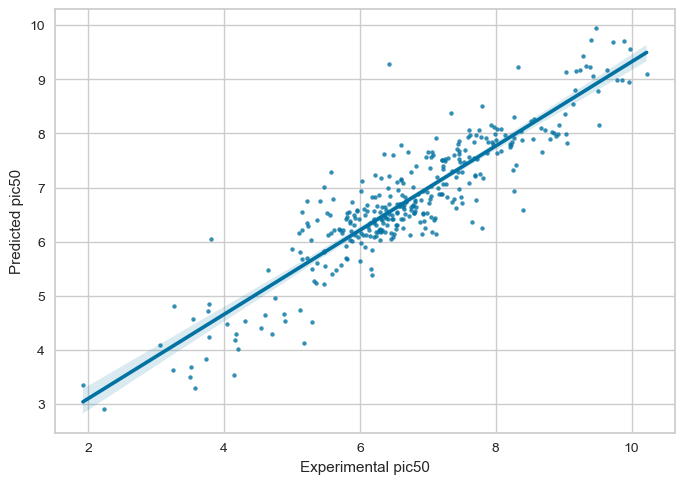

In [50]:
test_naive(df, gbm, property_names)

In [27]:
xgb_best = xgb.XGBRegressor(**{'colsample_bytree': 0.7, 'learning_rate': 0.1, 'max_depth': 7, 'n_estimators': 500})

Train test split process 
train size,  1370 test size,  343
fitting ... 
fit finished ...
0.8188841243935373
0.5883727446455743


(0.8188841243935373,
 0.5883727446455743,
 <Axes: xlabel='Experimental pic50', ylabel='Predicted pic50'>)

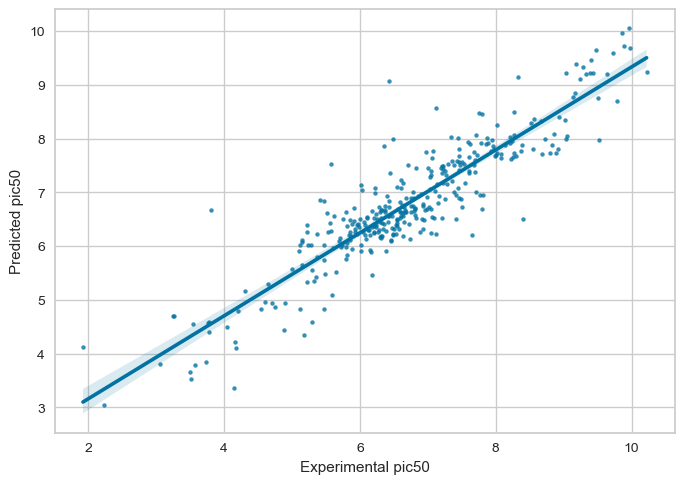

In [28]:
test_naive(df, xgb_best, property_names)

In [29]:
rf_best = RandomForestRegressor(**{'max_depth': 30, 'min_samples_split': 2, 'n_estimators': 500})

Train test split process 
train size,  1370 test size,  343
fitting ... 
fit finished ...
0.8163173354299276
0.5925273099885485


(0.8163173354299276,
 0.5925273099885485,
 <Axes: xlabel='Experimental pic50', ylabel='Predicted pic50'>)

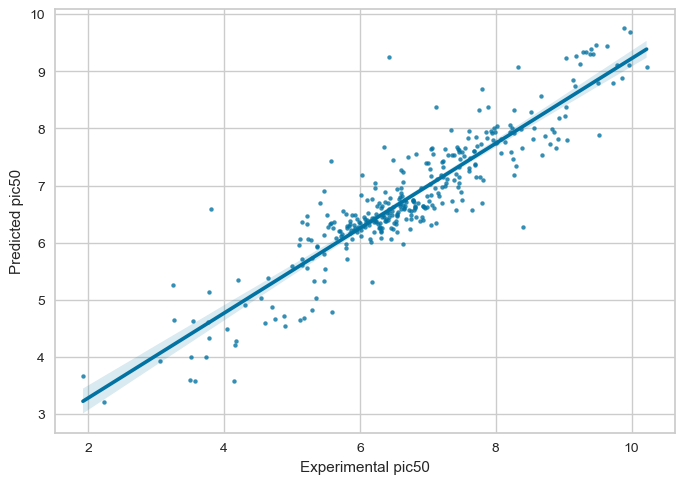

In [30]:
test_naive(df, rf_best, property_names)

### Testing drugs with these 3 models

In [31]:
df_drugs = pd.read_csv('drugs.csv')

In [32]:
df_drugs.head()

,type,drugbank_id,groups,name,SMILES,exactmw,amw,lipinskiHBA,lipinskiHBD,NumRotatableBonds,...,chi0n,chi1n,chi2n,chi3n,chi4n,hallKierAlpha,kappa1,kappa2,kappa3,Phi
0,small molecule,DB00006,"['approved', 'investigational']",Bivalirudin,CC[C@H](C)[C@H](NC(=O)[C@H](CCC(O)=O)NC(=O)[C@...,2178.985813,2180.317,57.0,31.0,66.0,...,85.843918,50.201079,25.145698,25.145698,16.910073,-17.09,126.572938,63.918233,44.397311,52.195604
1,small molecule,DB00014,['approved'],Goserelin,CC(C)C[C@H](NC(=O)[C@@H](COC(C)(C)C)NC(=O)[C@H...,1268.641439,1269.433,32.0,20.0,31.0,...,51.390949,29.860583,14.843672,14.843672,10.233085,-9.85,70.240083,33.108273,21.712549,25.555251
2,small molecule,DB00027,['approved'],Gramicidin_D,CC(C)C[C@@H](NC(=O)CNC(=O)[C@@H](NC=O)C(C)C)C(...,1810.033419,1811.253,35.0,20.0,51.0,...,78.097824,45.344840,22.830505,22.830505,15.843759,-12.95,103.428788,49.171455,30.053956,38.822473
3,small molecule,DB00035,['approved'],Desmopressin,NC(=O)CC[C@@H]1NC(=O)[C@H](CC2=CC=CC=C2)NC(=O)...,1068.426955,1069.238,26.0,18.0,19.0,...,40.355262,23.586716,11.532654,11.532654,7.808476,-7.62,58.946563,29.787374,20.117895,23.727883
4,small molecule,DB00050,"['approved', 'investigational']",Cetrorelix,CC(C)C[C@H](NC(=O)[C@@H](CCCNC(N)=O)NC(=O)[C@H...,1429.669818,1431.064,31.0,20.0,38.0,...,57.224959,33.481580,16.719602,16.719602,11.422794,-10.95,80.029969,39.739091,25.968750,31.179590


In [2]:
def main_test(df, model, selected_desc):
    df['mol'] = df.SMILES.apply(Chem.MolFromSmiles)
    print(f"Input dataframe shape: {df.shape}")
    curr_df = df.copy()
    curr_df['fp'] = df.mol.apply(dm.to_fp, fp_type='fcfp')
    print("shape after adding fp, ", curr_df.shape)
    curr_fp_df = pd.DataFrame(curr_df['fp'].to_list(), columns=[f'fp{x}' for x in range(len(curr_df['fp'][0]))], index=curr_df.index)
    print("curr_fp_df shape", curr_fp_df.shape)
    curr_df = pd.concat([curr_df[[*selected_desc, 'SMILES']], curr_fp_df], axis=1)
    print("shape after concat", curr_df.shape)
    del curr_fp_df
    print(f"Output dataframe shape: {curr_df.shape}")
    pred = model.predict(curr_df.drop(columns=['SMILES']))


    return pred

In [66]:
pic50_pred = main_test(df_drugs, xgb_best, property_names)

[23:23:55] WARNING: not removing hydrogen atom without neighbors
[23:23:55] WARNING: not removing hydrogen atom without neighbors


Input dataframe shape: (2800, 51)
shape after adding fp,  (2800, 52)
curr_fp_df shape (2800, 2048)
shape after concat (2800, 2092)
Output dataframe shape: (2800, 2092)


In [67]:
df_drugs['pred_pic50'] = pic50_pred

In [68]:
df_drugs['IC50'] = df_drugs.pred_pic50.apply(dm.molar.log_to_molar, unit='nM')

In [69]:
df_drugs.query('IC50 < 300')

,type,drugbank_id,groups,name,SMILES,exactmw,amw,lipinskiHBA,lipinskiHBD,NumRotatableBonds,...,chi3n,chi4n,hallKierAlpha,kappa1,kappa2,kappa3,Phi,mol,pred_pic50,IC50
80,small molecule,DB00203,"['approved', 'investigational']",Sildenafil,CCCC1=NN(C)C2=C1N=C(NC2=O)C1=CC(=CC=C1OCC)S(=O...,474.204924,474.587000,10.0,1.0,7.0,...,5.855397,4.093096,-2.760000,23.399926,9.238628,4.397669,6.551007,<rdkit.Chem.rdchem.Mol object at 0x7567684a9230>,6.814023,153.453565
163,small molecule,DB00290,"['approved', 'investigational']",Bleomycin,[H][C@](C)(NC(=O)[C@@]([H])(NC(=O)C1=NC(=NC(N)...,1414.518432,1415.576000,38.0,25.0,35.0,...,15.267131,9.791308,-7.300000,77.704045,35.799593,20.627055,28.976804,<rdkit.Chem.rdchem.Mol object at 0x756768a1aab0>,7.042346,90.709657
182,small molecule,DB00309,"['approved', 'investigational']",Vindesine,[H][C@@]12N3CC[C@@]11C4=CC(=C(OC)C=C4N(C)[C@@]...,753.410149,753.941000,12.0,6.0,6.0,...,15.235358,13.051926,-3.940000,36.683910,12.278612,4.513285,8.189591,<rdkit.Chem.rdchem.Mol object at 0x756768a1b300>,6.772915,168.688174
232,small molecule,DB00361,"['approved', 'investigational']",Vinorelbine,[H][C@@]12N(C)C3=CC(OC)=C(C=C3[C@@]11CCN3CC=C[...,778.394165,778.947000,12.0,2.0,7.0,...,14.759819,12.844767,-4.650000,37.900334,13.188751,4.803710,8.769439,<rdkit.Chem.rdchem.Mol object at 0x756768518970>,6.697041,200.890299
399,small molecule,DB00541,"['approved', 'investigational']",Vincristine,[H][C@@]12N3CC[C@@]11C4=C(C=C(OC)C(=C4)[C@]4(C...,824.399644,824.972000,14.0,3.0,8.0,...,15.501373,13.364987,-4.760000,40.635846,14.149040,5.194743,9.582637,<rdkit.Chem.rdchem.Mol object at 0x7567685115b0>,6.892211,128.170643
427,small molecule,DB00570,['approved'],Vinblastine,[H][C@@]12N(C)C3=CC(OC)=C(C=C3[C@@]11CCN3CC=C[...,810.420379,810.989000,13.0,3.0,7.0,...,15.598756,13.506091,-4.430000,40.000455,13.801607,5.196999,9.357128,<rdkit.Chem.rdchem.Mol object at 0x7567685122d0>,6.812286,154.068587
474,small molecule,DB00619,['approved'],Imatinib,CN1CCN(CC2=CC=C(C=C2)C(=O)NC2=CC(NC3=NC=CC(=N3...,493.259009,493.615000,8.0,2.0,7.0,...,6.572995,4.277830,-4.140000,24.549827,11.281649,6.354665,7.485474,<rdkit.Chem.rdchem.Mol object at 0x7567685137d0>,6.522996,299.919050
556,small molecule,DB00705,['approved'],Delavirdine,CC(C)NC1=C(N=CC=C1)N1CCN(CC1)C(=O)C1=CC2=C(N1)...,456.194360,456.572000,9.0,3.0,6.0,...,5.251675,3.889739,-3.270000,21.942960,8.696909,4.960135,5.963623,<rdkit.Chem.rdchem.Mol object at 0x756768521e70>,6.885407,130.194474
714,small molecule,DB00876,['approved'],Eprosartan,CCCCC1=NC=C(\C=C(/CC2=CC=CS2)C(O)=O)N1CC1=CC=C...,424.145678,424.522000,6.0,2.0,10.0,...,4.806196,3.164253,-3.190000,21.517227,10.024372,5.448126,7.189890,<rdkit.Chem.rdchem.Mol object at 0x75676850a810>,6.656192,220.702968
1011,small molecule,DB01194,['approved'],Brinzolamide,CCN[C@H]1CN(CCCOC)S(=O)(=O)C2=C1C=C(S2)S(N)(=O)=O,383.064334,383.517000,8.0,3.0,7.0,...,3.525095,2.485265,-0.560000,18.774017,7.131800,3.924105,5.821414,<rdkit.Chem.rdchem.Mol object at 0x756768502f80>,6.796381,159.815714


In [65]:
rf_drugs = df_drugs.query('IC50 < 300')

In [70]:
xgb_drugs = df_drugs.query('IC50 < 300')

In [60]:
gbm_drugs = df_drugs.query('IC50 < 300')

In [99]:
gbm_drugs

,type,drugbank_id,groups,name,SMILES,exactmw,amw,lipinskiHBA,lipinskiHBD,NumRotatableBonds,...,chi3n,chi4n,hallKierAlpha,kappa1,kappa2,kappa3,Phi,mol,pred_pic50,IC50
77,small molecule,DB00200,['approved'],Hydroxocobalamin,[N+]1=2[Co-3]345([N+]6=C7[C@H]([C@@](CC(=O)N)(...,1345.567066,1346.377,28.0,16.0,16.0,...,23.041034,18.979034,-6.533506,65.525725,20.250267,7.759617,14.422972,<rdkit.Chem.rdchem.Mol object at 0x784de9b66c70>,7.042561,90.664951
182,small molecule,DB00309,"['approved', 'investigational']",Vindesine,[H][C@@]12N3CC[C@@]11C4=CC(=C(OC)C=C4N(C)[C@@]...,753.410149,753.941,12.0,6.0,6.0,...,15.235358,13.051926,-3.940000,36.683910,12.278612,4.513285,8.189591,<rdkit.Chem.rdchem.Mol object at 0x784de9b57d10>,7.192286,64.226418
192,small molecule,DB00320,"['approved', 'investigational']",Dihydroergotamine,[H][C@@]12CCCN1C(=O)[C@H](CC1=CC=CC=C1)N1C(=O)...,583.279469,583.689,10.0,3.0,4.0,...,10.623171,8.649192,-3.730000,26.864504,9.382821,3.855575,5.861973,<rdkit.Chem.rdchem.Mol object at 0x784de9b578b0>,7.153264,70.264538
232,small molecule,DB00361,"['approved', 'investigational']",Vinorelbine,[H][C@@]12N(C)C3=CC(OC)=C(C=C3[C@@]11CCN3CC=C[...,778.394165,778.947,12.0,2.0,7.0,...,14.759819,12.844767,-4.650000,37.900334,13.188751,4.803710,8.769439,<rdkit.Chem.rdchem.Mol object at 0x784de9b56730>,7.241224,57.382039
297,small molecule,DB00430,['approved'],Cefpiramide,[H][C@]12SCC(CSC3=NN=NN3C)=C(N1C(=O)[C@@]2([H]...,612.120937,612.650,15.0,5.0,9.0,...,6.531851,4.422333,-4.640000,28.873109,11.690583,5.597490,8.036750,<rdkit.Chem.rdchem.Mol object at 0x784de9b54a50>,7.257446,55.278267
399,small molecule,DB00541,"['approved', 'investigational']",Vincristine,[H][C@@]12N3CC[C@@]11C4=C(C=C(OC)C(=C4)[C@]4(C...,824.399644,824.972,14.0,3.0,8.0,...,15.501373,13.364987,-4.760000,40.635846,14.149040,5.194743,9.582637,<rdkit.Chem.rdchem.Mol object at 0x784de9b49d20>,7.178166,66.348968
427,small molecule,DB00570,['approved'],Vinblastine,[H][C@@]12N(C)C3=CC(OC)=C(C=C3[C@@]11CCN3CC=C[...,810.420379,810.989,13.0,3.0,7.0,...,15.598756,13.506091,-4.430000,40.000455,13.801607,5.196999,9.357128,<rdkit.Chem.rdchem.Mol object at 0x784de9b490e0>,7.176456,66.610768
757,small molecule,DB00923,['approved'],Ceforanide,[H][C@]12SCC(CSC3=NN=NN3CC(O)=O)=C(N1C(=O)[C@H...,519.099473,519.565,13.0,5.0,10.0,...,5.415181,3.799723,-3.430000,24.686908,10.452308,5.155513,7.372433,<rdkit.Chem.rdchem.Mol object at 0x784de9b33bc0>,7.083278,82.550984
800,small molecule,DB00970,"['approved', 'investigational']",Dactinomycin,[H][C@@]12CCCN1C(=O)[C@H](NC(=O)[C@@H](NC(=O)C...,1254.628475,1255.438,28.0,6.0,8.0,...,17.523235,12.277858,-8.720000,68.765238,27.571948,13.704301,21.066573,<rdkit.Chem.rdchem.Mol object at 0x784de9b32880>,7.301927,49.896864
1044,small molecule,DB01229,"['approved', 'vet_approved']",Paclitaxel,[H][C@]12[C@H](OC(=O)C3=CC=CC=C3)[C@]3(O)C[C@H...,853.330955,853.918,15.0,4.0,10.0,...,13.479855,10.182541,-5.740000,44.320358,16.512846,7.294408,11.804116,<rdkit.Chem.rdchem.Mol object at 0x784de9b17c30>,7.241228,57.381481


In [101]:
rf_drugs

,type,drugbank_id,groups,name,SMILES,exactmw,amw,lipinskiHBA,lipinskiHBD,NumRotatableBonds,...,chi3n,chi4n,hallKierAlpha,kappa1,kappa2,kappa3,Phi,mol,pred_pic50,IC50
45,small molecule,DB00163,"['approved', 'nutraceutical', 'vet_approved']",Vitamin_E,CC(C)CCC[C@@H](C)CCC[C@@H](C)CCC[C@]1(C)CCC2=C...,430.381081,430.717000,2.0,1.0,12.0,...,7.867341,5.273240,-1.180000,26.075361,11.616184,7.430443,9.770845,<rdkit.Chem.rdchem.Mol object at 0x784df09e9f50>,7.157844,69.527459
60,small molecule,DB00183,['approved'],Pentagastrin,CSCC[C@H](NC(=O)[C@H](CC1=CNC2=C1C=CC=C2)NC(=O...,767.331247,767.906000,16.0,9.0,20.0,...,7.968887,5.366354,-5.580000,42.829421,20.605340,14.445654,16.342866,<rdkit.Chem.rdchem.Mol object at 0x784df09e98c0>,7.433082,36.890777
96,small molecule,DB00220,['approved'],Nelfinavir,[H][C@@]12CCCC[C@]1([H])CN(C[C@@H](O)[C@H](CSC...,567.313078,567.796000,7.0,4.0,9.0,...,8.228259,6.061703,-2.550000,30.409539,13.407907,8.015265,10.193207,<rdkit.Chem.rdchem.Mol object at 0x784df09e8900>,7.230740,58.784081
101,small molecule,DB00225,"['approved', 'investigational']",Gadodiamide,[Gd+3].CNC(=O)CN(CCN(CCN(CC([O-])=O)CC(=O)NC)C...,574.102242,573.661000,13.0,2.0,16.0,...,3.815134,2.375651,-1.445325,30.745802,17.257235,16.362701,17.686251,<rdkit.Chem.rdchem.Mol object at 0x784df09e86d0>,7.633316,23.263979
229,small molecule,DB00358,"['approved', 'investigational']",Mefloquine,OC(C1CCCCN1)C1=CC(=NC2=C1C=CC=C2C(F)(F)F)C(F)(F)F,378.116682,378.316000,3.0,2.0,2.0,...,4.515545,3.258365,-1.870000,18.907311,6.696086,3.635842,4.869423,<rdkit.Chem.rdchem.Mol object at 0x784e007ca1f0>,7.209931,61.669363
266,small molecule,DB00398,"['approved', 'investigational']",Sorafenib,CNC(=O)C1=NC=CC(OC2=CC=C(NC(=O)NC3=CC(=C(Cl)C=...,464.086303,464.831000,7.0,3.0,5.0,...,4.068619,2.582988,-3.790000,22.885411,9.563603,5.883370,6.839594,<rdkit.Chem.rdchem.Mol object at 0x784e00948040>,7.641967,22.805157
299,small molecule,DB00432,"['approved', 'investigational']",Trifluridine,OC[C@H]1O[C@H](C[C@@H]1O)N1C=C(C(=O)NC1=O)C(F)...,296.062006,296.201000,7.0,3.0,2.0,...,2.967548,1.951403,-1.650000,14.752754,5.035210,2.619412,3.714161,<rdkit.Chem.rdchem.Mol object at 0x784e00948eb0>,7.083430,82.522001
303,small molecule,DB00436,['approved'],Bendroflumethiazide,NS(=O)(=O)C1=CC2=C(NC(CC3=CC=CC=C3)NS2(=O)=O)C...,421.037783,421.422000,7.0,4.0,3.0,...,3.893015,2.763647,-2.150000,19.607155,6.476220,4.076630,4.702972,<rdkit.Chem.rdchem.Mol object at 0x784e00949070>,7.160465,69.109040
312,small molecule,DB00445,['approved'],Epirubicin,COC1=CC=CC2=C1C(=O)C1=C(O)C3=C(C[C@](O)(C[C@@H...,543.174061,543.525000,12.0,7.0,5.0,...,7.805280,5.750259,-3.390000,27.187263,9.662463,4.111773,6.735793,<rdkit.Chem.rdchem.Mol object at 0x784e00949460>,7.234190,58.319004
518,small molecule,DB00665,"['approved', 'investigational']",Nilutamide,CC1(C)NC(=O)N(C1=O)C1=CC(=C(C=C1)[N+]([O-])=O)...,317.062340,317.223000,7.0,1.0,2.0,...,3.100710,2.032318,-2.650000,15.733461,4.681462,2.468066,3.347982,<rdkit.Chem.rdchem.Mol object at 0x784e43470970>,7.266067,54.191748


In [102]:
xgb_drugs

,type,drugbank_id,groups,name,SMILES,exactmw,amw,lipinskiHBA,lipinskiHBD,NumRotatableBonds,...,chi3n,chi4n,hallKierAlpha,kappa1,kappa2,kappa3,Phi,mol,pred_pic50,IC50
5,small molecule,DB00080,"['approved', 'investigational']",Daptomycin,CCCCCCCCCC(=O)N[C@@H](CC1=CNC2=C1C=CC=C2)C(=O)...,1619.710366,1620.693000,43.0,25.0,35.0,...,17.862111,11.735508,-12.700000,94.675538,47.612683,32.504546,39.197882,<rdkit.Chem.rdchem.Mol object at 0x784e44c5a3b0>,7.364038,43.247647
60,small molecule,DB00183,['approved'],Pentagastrin,CSCC[C@H](NC(=O)[C@H](CC1=CNC2=C1C=CC=C2)NC(=O...,767.331247,767.906000,16.0,9.0,20.0,...,7.968887,5.366354,-5.580000,42.829421,20.605340,14.445654,16.342866,<rdkit.Chem.rdchem.Mol object at 0x784e44c58ba0>,7.691227,20.359778
77,small molecule,DB00200,['approved'],Hydroxocobalamin,[N+]1=2[Co-3]345([N+]6=C7[C@H]([C@@](CC(=O)N)(...,1345.567066,1346.377000,28.0,16.0,16.0,...,23.041034,18.979034,-6.533506,65.525725,20.250267,7.759617,14.422972,<rdkit.Chem.rdchem.Mol object at 0x784e44c58430>,7.335429,46.192481
271,small molecule,DB00403,['approved'],Ceruletide,[H][C@](NC(=O)[C@H](CC1=CC=C(OS(O)(=O)=O)C=C1)...,1351.448538,1352.426000,34.0,19.0,38.0,...,14.268005,9.504027,-10.200000,74.527347,35.571958,24.447089,28.203018,<rdkit.Chem.rdchem.Mol object at 0x784e43450510>,7.211921,61.387403
474,small molecule,DB00619,['approved'],Imatinib,CN1CCN(CC2=CC=C(C=C2)C(=O)NC2=CC(NC3=NC=CC(=N3...,493.259009,493.615000,8.0,2.0,7.0,...,6.572995,4.277830,-4.140000,24.549827,11.281649,6.354665,7.485474,<rdkit.Chem.rdchem.Mol object at 0x784de9ae5460>,7.044600,90.240089
519,small molecule,DB00666,['approved'],Nafarelin,CC(C)C[C@H](NC(=O)[C@@H](CC1=CC2=C(C=CC=C2)C=C...,1321.635626,1322.496000,30.0,19.0,33.0,...,16.571273,11.634244,-10.910000,70.948347,33.783352,20.055263,24.967427,<rdkit.Chem.rdchem.Mol object at 0x784de9ae6810>,7.242189,57.254690
1064,small molecule,DB01249,['approved'],Iodixanol,CC(=O)N(CC(O)CN(C(C)=O)C1=C(I)C(C(=O)NCC(O)CO)...,1549.713303,1550.188000,21.0,13.0,22.0,...,8.418471,5.260692,-0.720000,57.407421,27.180972,15.150932,25.167573,<rdkit.Chem.rdchem.Mol object at 0x784de9af98c0>,7.006455,98.524577
1087,small molecule,DB01284,['approved'],Tetracosactide,CSCC[C@H](NC(=O)[C@H](CO)NC(=O)[C@H](CC1=CC=C(...,2931.580641,2933.492000,71.0,50.0,93.0,...,35.391180,23.930069,-20.140000,170.991888,89.296785,57.325600,73.408778,<rdkit.Chem.rdchem.Mol object at 0x784de9afa2d0>,7.140042,72.436540
1267,small molecule,DB03614,"['approved', 'investigational']",Mecobalamin,C1(CC[C@@]2([C@@H](CC(N)=O)[C@@]3([C@@]4([N+]5...,1343.587801,1344.405000,27.0,15.0,16.0,...,23.465805,19.444697,-6.493506,65.564113,20.269766,7.768571,14.445317,<rdkit.Chem.rdchem.Mol object at 0x784de9b07220>,7.292227,51.023792
1337,small molecule,DB04868,"['approved', 'investigational']",Nilotinib,CC1=CN(C=N1)C1=CC(NC(=O)C2=CC=C(C)C(NC3=NC=CC(...,529.183793,529.526000,8.0,2.0,6.0,...,5.871917,3.874102,-5.060000,25.583760,10.364742,5.926970,6.799207,<rdkit.Chem.rdchem.Mol object at 0x784de9b09150>,7.035871,92.072296


In [106]:
xgb_drugs.columns

Index(['type', 'drugbank_id', 'groups', 'name', 'SMILES', 'exactmw', 'amw',
       'lipinskiHBA', 'lipinskiHBD', 'NumRotatableBonds', 'NumHBD', 'NumHBA',
       'NumHeavyAtoms', 'NumAtoms', 'NumHeteroatoms', 'NumAmideBonds',
       'FractionCSP3', 'NumRings', 'NumAromaticRings', 'NumAliphaticRings',
       'NumSaturatedRings', 'NumHeterocycles', 'NumAromaticHeterocycles',
       'NumSaturatedHeterocycles', 'NumAliphaticHeterocycles', 'NumSpiroAtoms',
       'NumBridgeheadAtoms', 'NumAtomStereoCenters',
       'NumUnspecifiedAtomStereoCenters', 'labuteASA', 'tpsa', 'CrippenClogP',
       'CrippenMR', 'chi0v', 'chi1v', 'chi2v', 'chi3v', 'chi4v', 'chi0n',
       'chi1n', 'chi2n', 'chi3n', 'chi4n', 'hallKierAlpha', 'kappa1', 'kappa2',
       'kappa3', 'Phi', 'mol', 'pred_pic50', 'IC50'],
      dtype='object')

In [74]:
pd.concat(
    [xgb_drugs.drop(columns=['pred_pic50', 'mol']).assign(model = lambda adf: 'xgb'),
     gbm_drugs.drop(columns=['pred_pic50', 'mol']).assign(model = lambda adf: 'gbm'),
     rf_drugs.drop(columns=['pred_pic50', 'mol']).assign(model = lambda adf: 'rf')]
).sort_values('IC50').query("NumRotatableBonds <= 10").query("NumRotatableBonds < 15 and amw <= 600").reset_index(drop=True).to_csv("syk_final.csv", index=False)

## Results 

#### Cross validation

In [329]:
def cross_validate_(df, model, selected_desc, n_splits=5, random_state=85):

    df['mol'] = df.SMILES.apply(Chem.MolFromSmiles)
    curr_df = df.copy()
    curr_df['fp'] = df.mol.apply(dm.to_fp, fp_type='avalon-count')
    curr_fp_df = pd.DataFrame(curr_df['fp'].to_list(), columns=[f'fp{x}' for x in range(len(curr_df['fp'][0]))])
    curr_df = pd.concat([curr_df[[*selected_desc, 'SMILES', 'pIC50']], curr_fp_df], axis=1)
    del curr_fp_df
    
    X = curr_df.drop(columns=['SMILES', 'pIC50'])
    y = curr_df.pIC50.astype(float)

    kf = KFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    
    fold_r2_scores = []
    fold_rmse_scores = []
    fold_predictions = []
    fold_actual = []
    
    print(f"Starting {n_splits}-fold cross-validation...")

    for fold, (train_idx, test_idx) in enumerate(kf.split(X)):
        print(f"\nFold {fold+1}/{n_splits}")
        
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
        
        print(f"  Training model on {len(X_train)} samples...")
        model.fit(X_train, y_train)
        
        y_pred = model.predict(X_test)
        
        r2 = r2_score(y_test, y_pred)
        rmse = np.sqrt(mean_squared_error(y_test, y_pred))
        
        print(f"  Fold {fold+1} - R²: {r2:.4f}, RMSE: {rmse:.4f}")
        
        fold_r2_scores.append(r2)
        fold_rmse_scores.append(rmse)
        fold_predictions.extend(y_pred)
        fold_actual.extend(y_test.values)
    
    mean_r2 = np.mean(fold_r2_scores)
    std_r2 = np.std(fold_r2_scores)
    mean_rmse = np.mean(fold_rmse_scores)
    std_rmse = np.std(fold_rmse_scores)
    
    overall_r2 = r2_score(fold_actual, fold_predictions)
    overall_rmse = np.sqrt(mean_squared_error(fold_actual, fold_predictions))
    
    results = {
        'fold_r2_scores': fold_r2_scores,
        'fold_rmse_scores': fold_rmse_scores,
        'mean_r2': mean_r2,
        'std_r2': std_r2,
        'mean_rmse': mean_rmse,
        'std_rmse': std_rmse,
        'overall_r2': overall_r2,
        'overall_rmse': overall_rmse,
    }
    
    # Print summary
    print("\n" + "="*50)
    print("Cross-Validation Summary:")
    print(f"Mean R²: {mean_r2:.4f} ± {std_r2:.4f}")
    print(f"Mean RMSE: {mean_rmse:.4f} ± {std_rmse:.4f}")
    print(f"Overall R² (all folds combined): {overall_r2:.4f}")
    print(f"Overall RMSE (all folds combined): {overall_rmse:.4f}")
    print("="*50)

    return results

In [330]:
rf_best = RandomForestRegressor(**{'max_depth': 30, 'min_samples_split': 2, 'n_estimators': 100})

In [331]:
rf_results = cross_validate_(df, rf_best, selected_desc)

Starting 5-fold cross-validation...

Fold 1/5
  Training model on 1368 samples...
  Fold 1 - R²: 0.8659, RMSE: 0.5147

Fold 2/5
  Training model on 1368 samples...
  Fold 2 - R²: 0.8378, RMSE: 0.5263

Fold 3/5
  Training model on 1368 samples...
  Fold 3 - R²: 0.8473, RMSE: 0.5632

Fold 4/5
  Training model on 1368 samples...
  Fold 4 - R²: 0.8319, RMSE: 0.5493

Fold 5/5
  Training model on 1368 samples...
  Fold 5 - R²: 0.8602, RMSE: 0.5052

Cross-Validation Summary:
Mean R²: 0.8486 ± 0.0129
Mean RMSE: 0.5317 ± 0.0216
Overall R² (all folds combined): 0.8494
Overall RMSE (all folds combined): 0.5322


In [332]:
xgboost_best = xgb.XGBRegressor(**{'colsample_bytree': 0.7, 'learning_rate': 0.05, 'max_depth': 7, 'n_estimators': 500})

In [333]:
xgb_results = cross_validate_(df, xgboost_best, selected_desc)

Starting 5-fold cross-validation...

Fold 1/5
  Training model on 1368 samples...
  Fold 1 - R²: 0.8584, RMSE: 0.5287

Fold 2/5
  Training model on 1368 samples...
  Fold 2 - R²: 0.8624, RMSE: 0.4847

Fold 3/5
  Training model on 1368 samples...
  Fold 3 - R²: 0.8552, RMSE: 0.5485

Fold 4/5
  Training model on 1368 samples...
  Fold 4 - R²: 0.8346, RMSE: 0.5449

Fold 5/5
  Training model on 1368 samples...
  Fold 5 - R²: 0.8642, RMSE: 0.4978

Cross-Validation Summary:
Mean R²: 0.8550 ± 0.0107
Mean RMSE: 0.5209 ± 0.0255
Overall R² (all folds combined): 0.8553
Overall RMSE (all folds combined): 0.5216


In [334]:
gbm_results = cross_validate_(df, gbm, selected_desc)

Starting 5-fold cross-validation...

Fold 1/5
  Training model on 1368 samples...
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.007595 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 8127
[LightGBM] [Info] Number of data points in the train set: 1368, number of used features: 522
[LightGBM] [Info] Start training from score 6.612648
  Fold 1 - R²: 0.8700, RMSE: 0.5066

Fold 2/5
  Training model on 1368 samples...
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.007290 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 8182
[LightGBM] [Info] Number of data points in the train set: 1368, number of used features: 521
[LightGBM] [Info] Start training from score 6.655362
  Fold 2 - R²: 0.8492, R

### Best model is lightGBM with above parameters, avalon-count fingerprint and selected-desc descriptors

## Testing drugs

In [165]:
df_drug = pd.read_csv('./drugs.csv', engine='pyarrow', dtype_backend='pyarrow')

In [166]:
df_drug.head()

,type,drugbank_id,groups,name,SMILES
0,small molecule,DB00006,"['approved', 'investigational']",Bivalirudin,CC[C@H](C)[C@H](NC(=O)[C@H](CCC(O)=O)NC(=O)[C@...
1,small molecule,DB00014,['approved'],Goserelin,CC(C)C[C@H](NC(=O)[C@@H](COC(C)(C)C)NC(=O)[C@H...
2,small molecule,DB00027,['approved'],Gramicidin_D,CC(C)C[C@@H](NC(=O)CNC(=O)[C@@H](NC=O)C(C)C)C(...
3,small molecule,DB00035,['approved'],Desmopressin,NC(=O)CC[C@@H]1NC(=O)[C@H](CC2=CC=CC=C2)NC(=O)...
4,small molecule,DB00050,"['approved', 'investigational']",Cetrorelix,CC(C)C[C@H](NC(=O)[C@@H](CCCNC(N)=O)NC(=O)[C@H...


In [167]:
df_drug.shape

(2803, 5)

prepare df to test, adding descs

In [18]:
def safe_smi2props(smi):
    try:
        return smi2props(smi)
    except Exception:
        return None

In [169]:
df_drug['props'] = df_drug.SMILES.progress_apply(safe_smi2props)

  0%|          | 0/2803 [00:00<?, ?it/s]

[22:33:50] Explicit valence for atom # 84 N, 4, is greater than permitted
[22:33:50] SMILES Parse Error: syntax error while parsing: OC1=CC=CC(=C1)C-1=C2\CCC(=N2)\C(=C2/N\C(\C=C2)=C(/C2=N/C(/C=C2)=C(\C2=CC=C\-1N2)C1=CC(O)=CC=C1)C1=CC(O)=CC=C1)\C1=CC(O)=CC=C1
[22:33:50] SMILES Parse Error: check for mistakes around position 76:
[22:33:50] C(/C=C2)=C(\C2=CC=C\-1N2)C1=CC(O)=CC=C1)C
[22:33:50] ~~~~~~~~~~~~~~~~~~~~^
[22:33:50] SMILES Parse Error: Failed parsing SMILES 'OC1=CC=CC(=C1)C-1=C2\CCC(=N2)\C(=C2/N\C(\C=C2)=C(/C2=N/C(/C=C2)=C(\C2=CC=C\-1N2)C1=CC(O)=CC=C1)C1=CC(O)=CC=C1)\C1=CC(O)=CC=C1' for input: 'OC1=CC=CC(=C1)C-1=C2\CCC(=N2)\C(=C2/N\C(\C=C2)=C(/C2=N/C(/C=C2)=C(\C2=CC=C\-1N2)C1=CC(O)=CC=C1)C1=CC(O)=CC=C1)\C1=CC(O)=CC=C1'
[22:33:51] WARNING: not removing hydrogen atom without neighbors
[22:33:51] WARNING: not removing hydrogen atom without neighbors


In [170]:
df_drug.query("props.isna()")

,type,drugbank_id,groups,name,SMILES,props
1833,small molecule,DB09385,['approved'],Cyanocobalamin_Co-57,[57Co+3].[C-]#N.C[C@H](CNC(=O)CC[C@]1(C)[C@@H]...,None
2186,small molecule,DB11630,"['approved', 'investigational']",Temoporfin,OC1=CC=CC(=C1)C-1=C2\CCC(=N2)\C(=C2/N\C(\C=C2)...,None


Deleting the above 2 rows

In [171]:
df_drug_corrected = df_drug.query("props.notna()")

In [172]:
df_drug_corrected.shape

(2801, 6)

In [173]:
df_drug_corrected[selected_desc] = df_drug_corrected['props'].to_list()

/tmp/ipykernel_2219975/100574241.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_drug_corrected[selected_desc] = df_drug_corrected['props'].to_list()
/tmp/ipykernel_2219975/100574241.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_drug_corrected[selected_desc] = df_drug_corrected['props'].to_list()
/tmp/ipykernel_2219975/100574241.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the ca

In [174]:
df_drug_corrected.head()

,type,drugbank_id,groups,name,SMILES,props,CrippenClogP,tpsa,kappa3,chi4n,chi4v,chi2v,hallKierAlpha,Phi,FractionCSP3,CrippenMR,lipinskiHBD
0,small molecule,DB00006,"['approved', 'investigational']",Bivalirudin,CC[C@H](C)[C@H](NC(=O)[C@H](CCC(O)=O)NC(=O)[C@...,"[-8.116429999999925, 901.5700000000002, 44.397...",-8.11643,901.57,44.397311,16.910073,16.910073,25.145698,-17.09,52.195604,0.540816,539.8094,31.0
1,small molecule,DB00014,['approved'],Goserelin,CC(C)C[C@H](NC(=O)[C@@H](COC(C)(C)C)NC(=O)[C@H...,"[-3.1057000000000192, 495.8899999999998, 21.71...",-3.10570,495.89,21.712549,10.233085,10.233085,14.843672,-9.85,25.555251,0.508475,328.5382,20.0
2,small molecule,DB00027,['approved'],Gramicidin_D,CC(C)C[C@@H](NC(=O)CNC(=O)[C@@H](NC=O)C(C)C)C(...,"[4.867599999999979, 519.8899999999998, 30.0539...",4.86760,519.89,30.053956,15.843759,15.843759,22.830505,-12.95,38.822473,0.510417,500.1181,20.0
3,small molecule,DB00035,['approved'],Desmopressin,NC(=O)CC[C@@H]1NC(=O)[C@H](CC2=CC=CC=C2)NC(=O)...,"[-4.1320300000000145, 435.40999999999985, 20.1...",-4.13203,435.41,20.117895,7.808476,9.953750,13.947776,-7.62,23.727883,0.478261,271.4037,18.0
4,small molecule,DB00050,"['approved', 'investigational']",Cetrorelix,CC(C)C[C@H](NC(=O)[C@@H](CCCNC(N)=O)NC(=O)[C@H...,"[-0.5061300000000057, 495.6699999999998, 25.96...",-0.50613,495.67,25.968750,11.422794,11.548782,16.971579,-10.95,31.179590,0.428571,377.7252,20.0


In [175]:
df_drug_corrected = df_drug_corrected.drop(columns='props')

In [183]:
df_drug_corrected.shape

(2801, 16)

In [335]:
def main_test(df, model, selected_desc):
    df['mol'] = df.SMILES.apply(Chem.MolFromSmiles)
    print(f"Input dataframe shape: {df.shape}")
    curr_df = df.copy()
    curr_df['fp'] = df.mol.apply(dm.to_fp, fp_type='avalon-count')
    print("shape after adding fp, ", curr_df.shape)
    curr_fp_df = pd.DataFrame(curr_df['fp'].to_list(), columns=[f'fp{x}' for x in range(len(curr_df['fp'][0]))], index=curr_df.index)
    print("curr_fp_df shape", curr_fp_df.shape)
    curr_df = pd.concat([curr_df[[*selected_desc, 'SMILES']], curr_fp_df], axis=1)
    print("shape after concat", curr_df.shape)
    del curr_fp_df
    print(f"Output dataframe shape: {curr_df.shape}")
    pred = model.predict(curr_df.drop(columns=['SMILES']))


    return pred

In [239]:
pic50_pred = main_test(df_drug_corrected, gbm, selected_desc)

[23:06:30] WARNING: not removing hydrogen atom without neighbors
[23:06:30] WARNING: not removing hydrogen atom without neighbors


Input dataframe shape: (2800, 19)
shape after adding fp,  (2800, 20)
curr_fp_df shape (2800, 2048)
shape after concat (2800, 2060)
Output dataframe shape: (2800, 2060)


seems like some drugs cannot be converted to fps.

In [186]:
def safe_to_fp(mol):
    try:
        return dm.to_fp(mol, fp_type='avalon-count')
    except Exception:
        return None

In [187]:
df_drug_corrected.shape

(2801, 17)

In [188]:
df_drug_corrected['fp'] = df_drug_corrected.mol.progress_apply(safe_to_fp)

  0%|          | 0/2801 [00:00<?, ?it/s]

In [189]:
df_drug_corrected.query("fp.isna()")

,type,drugbank_id,groups,name,SMILES,CrippenClogP,tpsa,kappa3,chi4n,chi4v,chi2v,hallKierAlpha,Phi,FractionCSP3,CrippenMR,lipinskiHBD,mol,fp
1782,small molecule,DB09278,['approved'],Activated_charcoal,[C],0.08129,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.243,0.0,<rdkit.Chem.rdchem.Mol object at 0x73344c3ea500>,None


I will delete the above row and test again

In [190]:
df_drug_corrected = df_drug_corrected.query("fp.notna()").drop(columns=['fp'])

In [191]:
df_drug_corrected.shape

(2800, 17)

In [360]:
pic50_pred = main_test(df_drug_corrected, gbm, selected_desc)

[01:14:19] WARNING: not removing hydrogen atom without neighbors
[01:14:19] WARNING: not removing hydrogen atom without neighbors


Input dataframe shape: (2800, 19)
shape after adding fp,  (2800, 20)
curr_fp_df shape (2800, 512)
shape after concat (2800, 524)
Output dataframe shape: (2800, 524)


In [361]:
df_drug_corrected['predicted_pic50'] = pic50_pred

In [362]:
df_drug_corrected.head()

,type,drugbank_id,groups,name,SMILES,CrippenClogP,tpsa,kappa3,chi4n,chi4v,chi2v,hallKierAlpha,Phi,FractionCSP3,CrippenMR,lipinskiHBD,mol,predicted_pic50,IC50
0,small molecule,DB00006,"['approved', 'investigational']",Bivalirudin,CC[C@H](C)[C@H](NC(=O)[C@H](CCC(O)=O)NC(=O)[C@...,-8.11643,901.57,44.397311,16.910073,16.910073,25.145698,-17.09,52.195604,0.540816,539.8094,31.0,<rdkit.Chem.rdchem.Mol object at 0x73344d534190>,5.976250,1075.536791
1,small molecule,DB00014,['approved'],Goserelin,CC(C)C[C@H](NC(=O)[C@@H](COC(C)(C)C)NC(=O)[C@H...,-3.10570,495.89,21.712549,10.233085,10.233085,14.843672,-9.85,25.555251,0.508475,328.5382,20.0,<rdkit.Chem.rdchem.Mol object at 0x73344d534200>,6.026887,830.963390
2,small molecule,DB00027,['approved'],Gramicidin_D,CC(C)C[C@@H](NC(=O)CNC(=O)[C@@H](NC=O)C(C)C)C(...,4.86760,519.89,30.053956,15.843759,15.843759,22.830505,-12.95,38.822473,0.510417,500.1181,20.0,<rdkit.Chem.rdchem.Mol object at 0x73344d534270>,6.273700,872.173284
3,small molecule,DB00035,['approved'],Desmopressin,NC(=O)CC[C@@H]1NC(=O)[C@H](CC2=CC=CC=C2)NC(=O)...,-4.13203,435.41,20.117895,7.808476,9.953750,13.947776,-7.62,23.727883,0.478261,271.4037,18.0,<rdkit.Chem.rdchem.Mol object at 0x73344d5342e0>,5.873628,1229.611547
4,small molecule,DB00050,"['approved', 'investigational']",Cetrorelix,CC(C)C[C@H](NC(=O)[C@@H](CCCNC(N)=O)NC(=O)[C@H...,-0.50613,495.67,25.968750,11.422794,11.548782,16.971579,-10.95,31.179590,0.428571,377.7252,20.0,<rdkit.Chem.rdchem.Mol object at 0x73344d534350>,5.744334,1837.044282


converting back to ic50

In [363]:
df_drug_corrected['IC50'] = df_drug_corrected.predicted_pic50.apply(dm.molar.log_to_molar, unit='nM')

In [364]:
df_drug_corrected.head()

,type,drugbank_id,groups,name,SMILES,CrippenClogP,tpsa,kappa3,chi4n,chi4v,chi2v,hallKierAlpha,Phi,FractionCSP3,CrippenMR,lipinskiHBD,mol,predicted_pic50,IC50
0,small molecule,DB00006,"['approved', 'investigational']",Bivalirudin,CC[C@H](C)[C@H](NC(=O)[C@H](CCC(O)=O)NC(=O)[C@...,-8.11643,901.57,44.397311,16.910073,16.910073,25.145698,-17.09,52.195604,0.540816,539.8094,31.0,<rdkit.Chem.rdchem.Mol object at 0x73344d534190>,5.976250,1056.208880
1,small molecule,DB00014,['approved'],Goserelin,CC(C)C[C@H](NC(=O)[C@@H](COC(C)(C)C)NC(=O)[C@H...,-3.10570,495.89,21.712549,10.233085,10.233085,14.843672,-9.85,25.555251,0.508475,328.5382,20.0,<rdkit.Chem.rdchem.Mol object at 0x73344d534200>,6.026887,939.968448
2,small molecule,DB00027,['approved'],Gramicidin_D,CC(C)C[C@@H](NC(=O)CNC(=O)[C@@H](NC=O)C(C)C)C(...,4.86760,519.89,30.053956,15.843759,15.843759,22.830505,-12.95,38.822473,0.510417,500.1181,20.0,<rdkit.Chem.rdchem.Mol object at 0x73344d534270>,6.273700,532.476063
3,small molecule,DB00035,['approved'],Desmopressin,NC(=O)CC[C@@H]1NC(=O)[C@H](CC2=CC=CC=C2)NC(=O)...,-4.13203,435.41,20.117895,7.808476,9.953750,13.947776,-7.62,23.727883,0.478261,271.4037,18.0,<rdkit.Chem.rdchem.Mol object at 0x73344d5342e0>,5.873628,1337.739883
4,small molecule,DB00050,"['approved', 'investigational']",Cetrorelix,CC(C)C[C@H](NC(=O)[C@@H](CCCNC(N)=O)NC(=O)[C@H...,-0.50613,495.67,25.968750,11.422794,11.548782,16.971579,-10.95,31.179590,0.428571,377.7252,20.0,<rdkit.Chem.rdchem.Mol object at 0x73344d534350>,5.744334,1801.632407


In [365]:
df_drug_corrected.describe()

,CrippenClogP,tpsa,kappa3,chi4n,chi4v,chi2v,hallKierAlpha,Phi,FractionCSP3,CrippenMR,lipinskiHBD,predicted_pic50,IC50
count,2800.000000,2800.000000,2800.000000,2800.000000,2800.000000,2800.000000,2800.000000,2800.000000,2800.000000,2800.000000,2800.00000,2800.000000,2800.000000
mean,1.805067,100.324482,85.874864,3.448394,3.948146,5.434039,-1.953212,346.784982,0.443160,99.265890,2.71500,5.413450,5271.808268
std,3.912652,117.960665,1395.547023,3.131337,3.598106,4.559276,2.061764,14419.228388,0.277930,75.947316,4.31282,0.426222,3237.257184
min,-35.163200,0.000000,-104.040000,0.000000,0.000000,0.000000,-28.690000,-25.958400,0.000000,0.000000,0.00000,4.609137,25.669330
25%,0.309277,43.370000,2.575904,1.452003,1.787904,2.874317,-2.680000,3.582637,0.250000,61.544575,1.00000,5.135532,2641.604482
50%,2.393400,75.660000,3.934465,2.792390,3.269623,4.686509,-1.750000,5.202560,0.428571,90.003050,2.00000,5.274428,5315.846134
75%,3.889525,113.647500,6.081516,4.499225,5.233338,6.968825,-1.020000,7.853136,0.631579,116.916600,3.00000,5.578132,7319.282174
max,57.751000,1690.640000,38466.921877,36.571330,58.852625,74.806890,8.784675,757610.383911,1.000000,1100.279700,67.00000,7.590585,24595.936509


In [366]:
df_drug_corrected.query("IC50 <= 1000").shape

(290, 19)

In [367]:
df_drug_corrected.query("IC50 <= 500").shape

(129, 19)

In [368]:
df_drug_corrected.query("IC50 <= 100").shape

(24, 19)

In [206]:
ecfp_rf_100 = df_drug_corrected.query("IC50 <= 100")

In [218]:
ecfp_rf_100.shape

(73, 19)

In [217]:
ecfp_gbm_100 = df_drug_corrected.query("IC50 <= 100")

In [219]:
ecfp_gbm_100.shape

(10, 19)

In [230]:
ecfp_xgb_100 = df_drug_corrected.query("IC50 <= 100")

In [231]:
ecfp_xgb_100.shape

(25, 19)

In [249]:
n_ecfp_gbm_100 = df_drug_corrected.query("IC50 <= 100")

In [250]:
n_ecfp_gbm_100.shape

(13, 19)

In [261]:
n_ecfp_xgb_100 = df_drug_corrected.query("IC50 <= 100")

In [262]:
n_ecfp_xgb_100.shape

(27, 19)

In [273]:
n_ecfp_rf_100 = df_drug_corrected.query("IC50 <= 100")

In [346]:
avalon_rf_100 = df_drug_corrected.query("IC50 <= 100")

In [347]:
avalon_rf_100.shape

(38, 19)

In [358]:
avalon_xgb_100 = df_drug_corrected.query("IC50 <= 100")

In [359]:
avalon_xgb_100.shape

(41, 19)

In [370]:
avalon_gbm_100 = df_drug_corrected.query("IC50 <= 100")

In [371]:
avalon_gbm_100.shape

(24, 19)

In [202]:
df_drug_corrected.query("IC50 <= 50").shape

(69, 19)

In [203]:
import mols2grid

In [369]:
mols2grid.display(df_drug_corrected.query("IC50 <= 100"), smiles_col='SMILES', size=(260, 180), subset=['name', 'IC50'], transform={"IC50": lambda x: f"{x:.2f} nM"})

MolGridWidget()

In [372]:
common = pd.concat([avalon_gbm_100[['name', 'SMILES']], avalon_rf_100[['name', 'SMILES']], avalon_gbm_100[['name', 'SMILES']]])

In [373]:
commen_ecfp_count = common[common.duplicated(keep=False)].drop_duplicates()

In [374]:
commen_ecfp = common[common.duplicated(keep=False)].drop_duplicates()

In [312]:
from rdkit import IPythonConsole

IPythonConsole.ipython_useSVG = False

In [320]:
ecfp_rf_100

,type,drugbank_id,groups,name,SMILES,CrippenClogP,tpsa,kappa3,chi4n,chi4v,chi2v,hallKierAlpha,Phi,FractionCSP3,CrippenMR,lipinskiHBD,mol,predicted_pic50,IC50
45,small molecule,DB00163,"['approved', 'nutraceutical', 'vet_approved']",Vitamin_E,CC(C)CCC[C@@H](C)CCC[C@@H](C)CCC[C@]1(C)CCC2=C...,8.84026,29.46,7.430443,5.273240,5.273240,7.867341,-1.180000,9.770845,0.793103,134.3908,1.0,<rdkit.Chem.rdchem.Mol object at 0x73346052c350>,8.189193,6.468556
74,small molecule,DB00197,"['approved', 'investigational', 'withdrawn']",Troglitazone,CC1=C(C)C2=C(CCC(C)(COC3=CC=C(CC4SC(=O)NC4=O)C...,4.37426,84.86,4.237238,4.095833,4.955511,7.229558,-2.670000,5.640935,0.416667,120.2305,2.0,<rdkit.Chem.rdchem.Mol object at 0x73346052d000>,7.608375,24.639129
101,small molecule,DB00225,"['approved', 'investigational']",Gadodiamide,[Gd+3].CNC(=O)CN(CCN(CCN(CC([O-])=O)CC(=O)NC)C...,-7.36590,188.31,16.362701,2.375651,2.375651,3.815134,-1.445325,17.686251,0.687500,92.4744,2.0,<rdkit.Chem.rdchem.Mol object at 0x73346052dbd0>,8.157093,6.964780
229,small molecule,DB00358,"['approved', 'investigational']",Mefloquine,OC(C1CCCCN1)C1=CC(=NC2=C1C=CC=C2C(F)(F)F)C(F)(F)F,4.44790,45.15,3.635842,3.258365,3.258365,4.515545,-1.870000,4.869423,0.470588,82.3485,2.0,<rdkit.Chem.rdchem.Mol object at 0x733460531460>,7.616010,24.209758
259,small molecule,DB00391,"['approved', 'investigational']",Sulpiride,CCN1CCCC1CNC(=O)C1=C(OC)C=CC(=C1)S(N)(=O)=O,0.55670,101.73,4.213285,2.889874,3.429712,5.058598,-1.640000,5.611214,0.533333,86.9694,3.0,<rdkit.Chem.rdchem.Mol object at 0x733460532180>,7.674016,21.182823
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2734,small molecule,DB15873,['approved'],Copper_oxodotreotide_Cu-64,[64Cu++].C[C@@H](O)[C@H](NC(=O)[C@@H]1CSSC[C@H...,-6.04650,503.12,28.147695,11.088390,13.416268,18.966217,-8.420519,34.705501,0.507692,361.6337,16.0,<rdkit.Chem.rdchem.Mol object at 0x73346058a490>,8.037542,9.171880
2748,small molecule,DB16200,"['approved', 'investigational']",Iptacopan,CCO[C@H]1CCN(CC2=C(OC)C=C(C)C3=C2C=CN3)[C@@H](...,4.92532,74.79,4.313545,4.736777,4.736777,6.302604,-2.830000,6.296914,0.400000,120.7880,2.0,<rdkit.Chem.rdchem.Mol object at 0x73346058aab0>,7.717177,19.178882
2750,small molecule,DB16217,"['approved', 'investigational']",Leniolisib,CCC(=O)N1CC[C@@H](C1)NC1=C2CN(CCC2=NC=N1)C1=CN...,2.88450,83.48,4.415594,4.187369,4.187369,5.886951,-3.110000,6.071919,0.523810,111.4757,1.0,<rdkit.Chem.rdchem.Mol object at 0x73346058ab90>,7.691852,20.330519
2751,small molecule,DB16226,"['approved', 'investigational']",Maralixibat,CCCCC1(CCCC)CS(=O)(=O)C2=CC=C(C=C2[C@H]([C@H]1...,6.62450,70.08,7.324331,8.425031,10.617229,13.511206,-2.910000,10.566861,0.550000,194.3760,1.0,<rdkit.Chem.rdchem.Mol object at 0x73346058ac00>,7.076901,83.771988


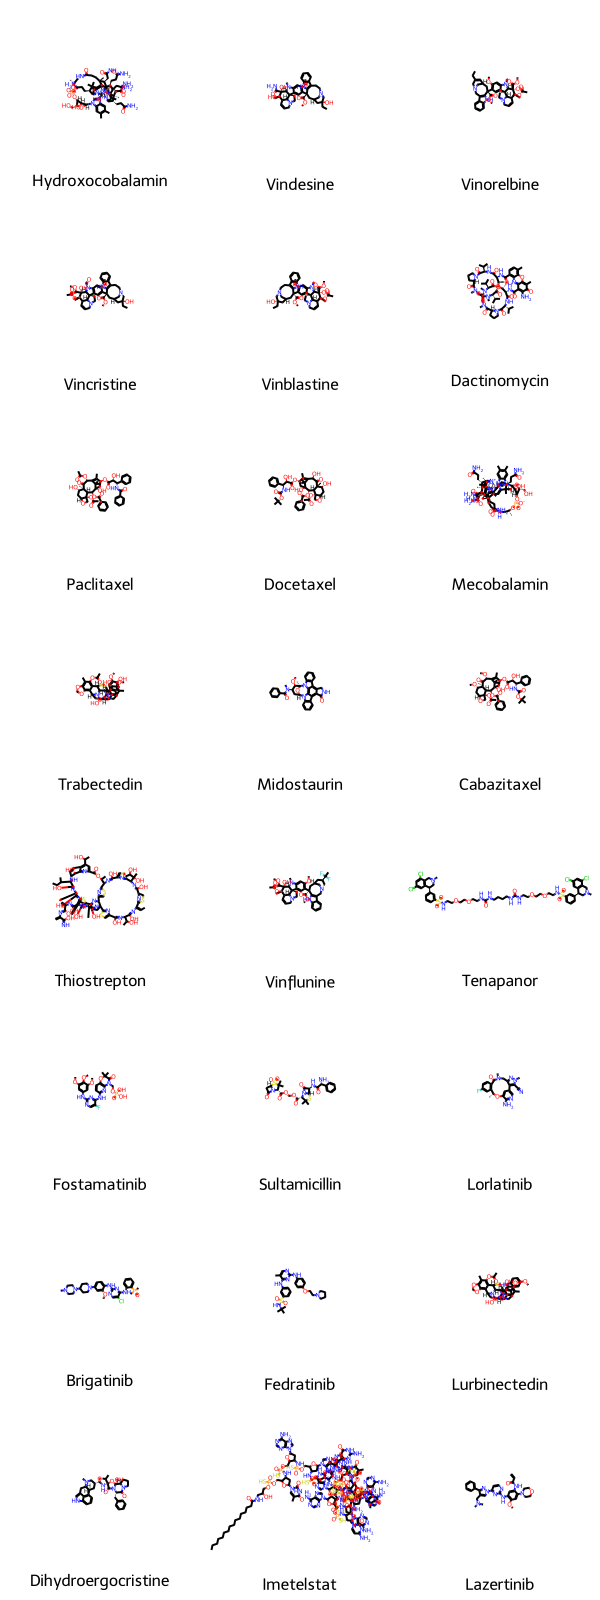

In [375]:
Chem.Draw.MolsToGridImage(
    [Chem.MolFromSmiles(x) for x in commen_ecfp_count.SMILES.values],
    legends = [f"{name}" for name in commen_ecfp_count.name.values]
)